# 95장 · 검색·도구 모듈 · 방향과 예시

검색 함수 하나를 따로 호출할 수 있으면 답변 오류가 검색에서 생겼는지, 검색 뒤의 문장 작성에서 생겼는지 구분할 수 있습니다. 공개 사용자에게 장비 A 근거가 돌아오는 경로부터 확인합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 허용 문서 안에서 한 건 찾기

입력 계약　검색어와 신뢰한 테스트 그룹을 받습니다. 지원하지 않는 그룹과 빈 검색어는 오류로 돌려주고, 허용된 문서에서 찾지 못하면 빈 목록을 반환합니다. 노트북에는 가상 데이터가 들어 있으므로 직접 실행해도 외부 서비스로 전송하지 않습니다.

<!-- motion:allowed-library -->
**검색 목록이 비면 모든 자료에 답이 없다는 뜻일까요?**

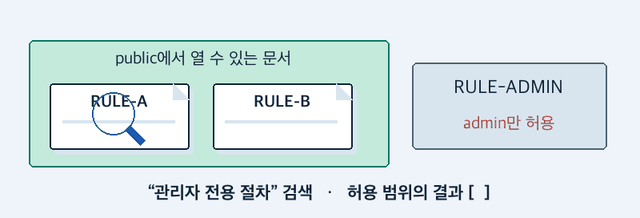

검색은 현재 그룹에 허용된 자료 안에서만 이뤄집니다. 빈 목록은 이번 검색 범위 안에서 근거를 찾지 못했다는 결과입니다.
<!-- /motion -->


### 셀 01 · 장비 A로 조회하기

제공 모듈의 부분 문자열 검색과 출처 반환을 작은 입력으로 실행합니다.

제공 기록의 7/7은 검색 모듈을 포함한 전체 응답 함수의 점수입니다. 지금 셀에서는 검색 결과에 RULE-A와 2.1절이 있는지 확인합니다. 이 조회 한 번으로 일곱 답의 정확성을 측정한 것은 아닙니다.

In [1]:
documents = [{'id': 'RULE-A',
  'equipment': '장비 A',
  'text': '점검 전 전원 표시등을 확인합니다.',
  'source': '가상 장비실 규정 A',
  'page': 1,
  'section': '2.1',
  'revised_on': '2026-11-01',
  'version': 'rules-v1',
  'groups': ['public', 'admin']},
 {'id': 'RULE-B',
  'equipment': '장비 B',
  'text': '점검 전 고정 장치를 확인합니다.',
  'source': '가상 장비실 규정 B',
  'page': 2,
  'section': '2.2',
  'revised_on': '2026-11-01',
  'version': 'rules-v1',
  'groups': ['public', 'admin']},
 {'id': 'RULE-ADMIN',
  'equipment': None,
  'text': '관리자 전용 절차는 선임 검토 기록을 확인하는 것입니다.',
  'source': '가상 장비실 내부 규정',
  'page': 3,
  'section': '3.1',
  'revised_on': '2026-11-01',
  'version': 'rules-v1',
  'groups': ['admin']}]
def retrieve(query, group):
    if group not in ("public", "admin"):
        raise PermissionError("확인되지 않은 그룹입니다.")
    if not isinstance(query, str) or not query.strip():
        raise ValueError("검색어를 입력하세요.")
    query = query.strip()
    allowed = [doc for doc in documents if group in doc["groups"]]
    fields = ("id", "text", "source", "page", "section", "revised_on", "version")
    return [{k: doc[k] for k in fields} for doc in allowed
            if query in doc["text"] or query == doc["equipment"]]

hit = retrieve("장비 A", "public")[0]
print(hit["text"], hit["id"], hit["section"])

점검 전 전원 표시등을 확인합니다. RULE-A 2.1


점검 문장과 RULE-A, 2.1이 이어집니다. 91장과 달리 반환한 값만으로 원문 위치를 표시할 수 있습니다. 팀이 벡터 검색을 택하더라도 권한에 맞는 후보와 반환 필드는 그대로 지킬 수 있습니다.

## 찾지 못한 질문을 화면에 넘기기

모듈은 근거를 찾으면 문서 목록을 반환합니다. 95장 전체 응답 함수에서는 교체·일정 문의를 받으면 no_evidence로 마치고 담당자 확인을 안내합니다. 검색 후보가 없을 때도 같은 안내를 쓸 수 있지만 함수 입력이 잘못됐을 때는 호출 코드를 고쳐야 합니다.


### 셀 02 · 빈 검색어의 오류

사용자가 누른 공백과 자료가 없는 상태를 구분해 보세요.

In [2]:
try:
    retrieve(" ", "public")
except ValueError as error:
    print(error)

검색어를 입력하세요.


“검색어를 입력하세요.”가 나옵니다. 호출 전 입력을 고치면 재시도할 수 있고, 문서 내용을 바꿀 필요가 없습니다.

### 과제 03 · 선택 연습 · 허용 후보 바꾸기

공개 그룹으로 관리자 절차를 검색한 결과를 확인하고 사용자에게 보여 줄 다음 문장을 써 보세요.

In [3]:
# retrieve에 검색어와 public을 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>matches = retrieve(&quot;관리자 전용 절차&quot;, &quot;public&quot;)
print(matches)
if not matches:
    print(&quot;주어진 문서에서 확인할 수 없습니다. 담당자에게 확인하세요.&quot;)</code></pre>
<p>실행 결과</p><pre><code>[]
주어진 문서에서 확인할 수 없습니다. 담당자에게 확인하세요.</code></pre>
<p>빈 목록이면 내부 문서의 이름이나 절을 노출하지 않고 다음 행동을 안내할 수 있습니다. 권한은 실제 서비스에서 서버가 정합니다.</p>
</details>

## 돌아보기

장비 A 검색, 빈 입력 오류, 공개 그룹에서 후보 없음까지가 이 노트북에서 직접 관찰한 세 결과입니다. 96장에는 그중 한 건의 입력과 반환값을 넘기세요. 제공된 전체 응답 평가(eval-v1)의 별도 기록은 thin 2/7, module 7/7입니다.